In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
orders = pd.read_csv("olist_orders_dataset.csv")
order_items = pd.read_csv("olist_order_items_dataset.csv")
order_reviews = pd.read_csv("olist_order_reviews_dataset.csv")
products = pd.read_csv("olist_products_dataset.csv")
customers = pd.read_csv("olist_customers_dataset.csv")
sellers = pd.read_csv("olist_sellers_dataset.csv")
geo = pd.read_csv("olist_geolocation_dataset.csv")
payments = pd.read_csv("olist_order_payments_dataset.csv")

In [4]:
orders["order_purchase_timestamp"] = pd.to_datetime(
    orders["order_purchase_timestamp"],
    format="%Y-%m-%d %H:%M:%S",
    errors="coerce"
)

orders["order_delivered_customer_date"] = pd.to_datetime(
    orders["order_delivered_customer_date"],
    format="%Y-%m-%d %H:%M:%S",
    errors="coerce"
)

orders["order_estimated_delivery_date"] = pd.to_datetime(
    orders["order_estimated_delivery_date"],
    format="%Y-%m-%d %H:%M:%S",
    errors="coerce"
)

## 1.- linea : pedidos por mes

,order_purchase_timestamp,order_id,mes
74393,2018-05-12 17:01:57,f48b0e16f86dbb29cbbaba5a05506a3b,2018-05
67176,2018-07-31 20:50:52,2fdd596723c47b1dd0dcade4d2cd1df4,2018-07
40604,2017-10-12 08:29:47,59fb9bc4a2f049228ee64f5073bc9165,2017-10
78014,2018-03-19 18:21:19,c1ddb9a2ec3bae0156fed0df64910447,2018-03
7966,2018-01-13 09:45:34,482c3ed0fe2eb68b316507e78faa6783,2018-01


<Axes: title={'center': 'Numero de ventas'}, xlabel='mes', ylabel='Cantidad de ventas'>

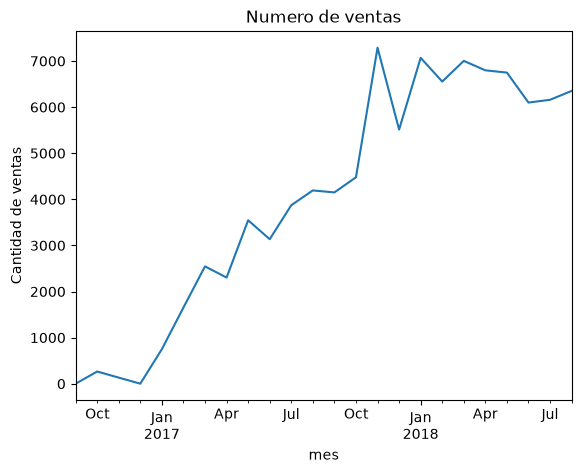

In [41]:
#solo ventas entregadas
df1 = orders[orders["order_status"] == "delivered"]
# para no saturar la vista ni la memoria, cortamos las columnas que ocupamos
df1 = df1[["order_purchase_timestamp", "order_id"]]
# Crear una columna mes apartir de order_purchase_timestamp
df1["mes"] = df1["order_purchase_timestamp"].dt.to_period('M')
# sample(5) muestra datos aleatorios del df
display(df1.sample(5))
#agrupar por mes y contar order_id
resultado1 = df1.groupby("mes")["order_id"].nunique()

#Ahora graficaremos ese pedo
resultado1.plot(
    kind="line",
    xlabel="mes",
    ylabel="Cantidad de ventas",
    title="Numero de ventas"
)


## 2 Barras horizontales: top 10 categorías por ingreso
* Merge order_items + products por product_id.
* Merge con product_category_name_translation por product_category_name (nombres en inglés).
* groupby categoría → suma de price.
* Tomar las 10 mayores con .nlargest(10).
* Inverti*r el orden para que la mayor quede arriba y graficar con barh.

<Axes: ylabel='product_category_name'>

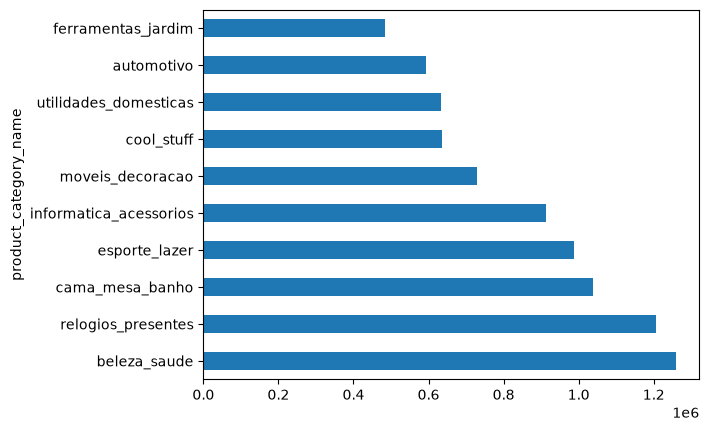

In [38]:
df1 = order_items[["product_id","price"]]
df2 = products[["product_id", "product_category_name"]]
df3 = df2.merge(df1, on="product_id", how="left")
resultado2= df3.groupby("product_category_name")["price"].sum().nlargest(10)

resultado2.plot(
    kind="barh"
)

## 3 Histograma: distribución del precio
* Usar order_items['price'].
* Primer histograma directo: se verá muy sesgado.
* Repetir con bins en escala log o con np.log10(price).
* Discusión: por qué la media engaña. Marcar media y mediana con axvline.

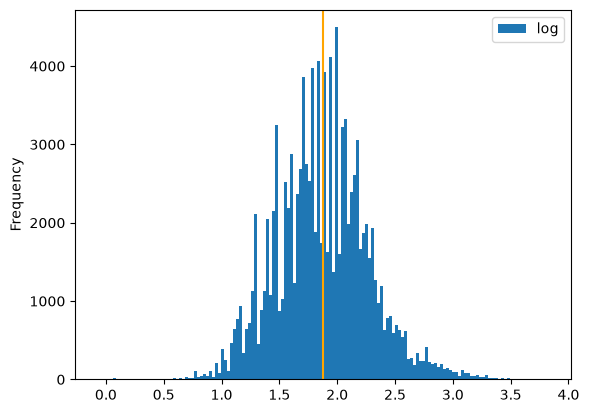

In [18]:
import numpy as np 
df3 = order_items
df3["log"] = df3["price"].apply(np.log10)
df3["log"].plot(
    kind ="hist",
    bins=150
)

media = df3["log"].mean()
mediana = df3["log"].median()
plt.axvline(media, color="Orange")
plt.legend()
plt.show()

<Axes: xlabel='order_status'>

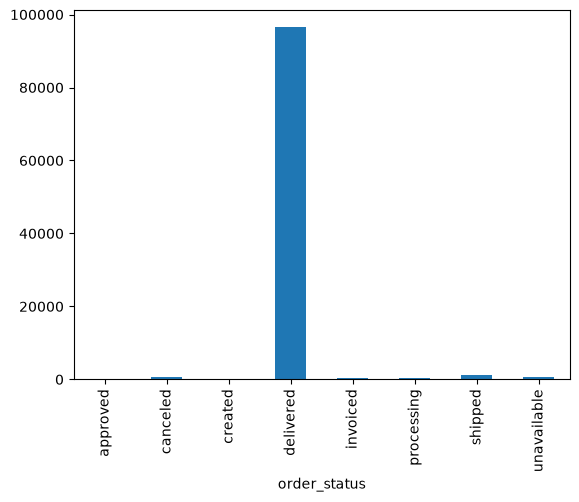

In [8]:
orders.groupby("order_status")["order_id"].count().plot(kind="bar")

## 4 Histograma comparativo: días de entrega reales vs. estimados
* En orders, convertir a datetime las columnas de compra, entrega real y entrega estimada.
* Calcular dias_reales = entregado − compra y dias_estimados = estimado − compra (en .dt.days).
* Eliminar NaN (pedidos no entregados).
* Dos histogramas en el mismo eje con alpha=0.5 y leyenda.

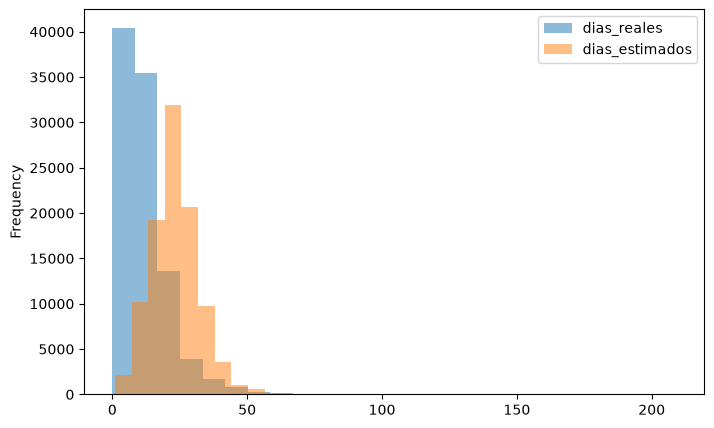

In [21]:
df4 = orders
df4.dropna(subset="order_estimated_delivery_date")
df4.isna().sum()
df4 = df4[["order_purchase_timestamp", "order_delivered_customer_date","order_estimated_delivery_date"]]
df4["dias_reales"] = (df4["order_delivered_customer_date"] - df4["order_purchase_timestamp"]).dt.days
df4["dias_estimados"] = (df4["order_estimated_delivery_date"] - df4["order_purchase_timestamp"]).dt.days

import matplotlib.pyplot as plt
lienzo, pintura = plt.subplots(figsize=(8,5))
df4["dias_reales"].plot(
    kind="hist",
    bins = 25,
    alpha= 0.5
)
df4["dias_estimados"].plot(
    kind="hist",
    alpha =0.5,
    bins = 25
)
plt.legend()

## 5 Boxplot: calificación vs. días de retraso plt.boxplot
* En orders, calcular retraso = entregado − estimado en días.
* Merge con order_reviews por order_id (quitar duplicados por order_id: hay pedidos con más de una reseña).
* Agrupar el retraso por review_score (1–5) → lista de 5 arrays.
* Pasar la lista a boxplot con etiquetas 1–5.
* Conclusión esperada: las calificaciones de 1 tienen retrasos mucho mayores.


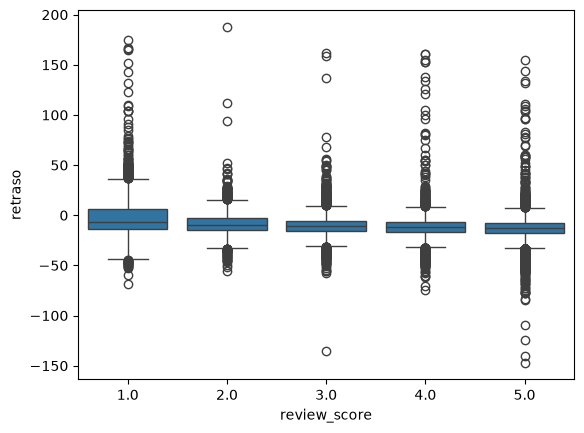

In [14]:
df5 = orders
df5.head()
df5["retraso"] = (df5["order_delivered_customer_date"] - df5["order_estimated_delivery_date"]).dt.days
df5 = df5.merge(order_reviews, on="order_id", how="left")
df5 = df5.drop_duplicates(subset="order_id")
sns.boxplot(data=df5, x="review_score", y="retraso")
plt.show()


## 6 Barras con error: calificación promedio a tiempo vs. tarde
* Usar el mismo merge de la gráfica 5.
* Crear columna booleana tarde = retraso > 0.
* groupby('tarde') → mean y std de review_score.
* Graficar barras con yerr=std.

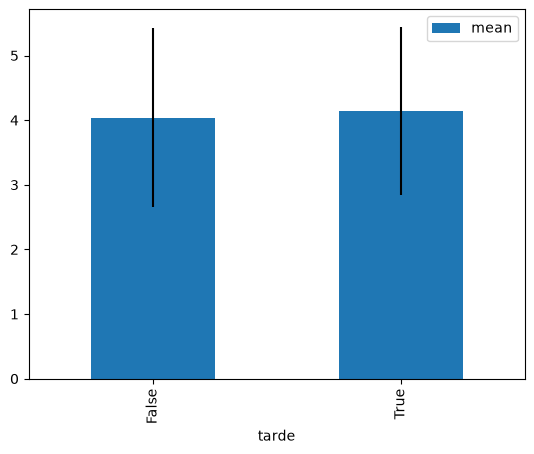

In [26]:
df6 = orders
df6["retraso"] =( df6["order_delivered_customer_date"] - df5["order_estimated_delivery_date"]).dt.days
df6 = df6.merge(order_reviews, on="order_id", how="left")
df6["tarde"] = df6["retraso"]>0
grafica= df6.groupby("tarde")["review_score"].agg(["mean","std"]).plot(kind="bar", yerr="std")
# lo escribí todo de nuevo porque me dio miedo solo poner df5=df6 :(.



## 7Pastel / dona: métodos de pago
* Order_payments → value_counts() de payment_type.
* Agrupar not_defined y categorías pequeñas en "otros".
* Graficar con autopct='%1.1f%%'; para dona, wedgeprops={'width':0.4}.
* Discusión: por qué los pasteles suelen ser mala idea; comparar con la versión en barras.

<Axes: title={'center': 'Métodos de pago'}, xlabel='Tipo de pago'>

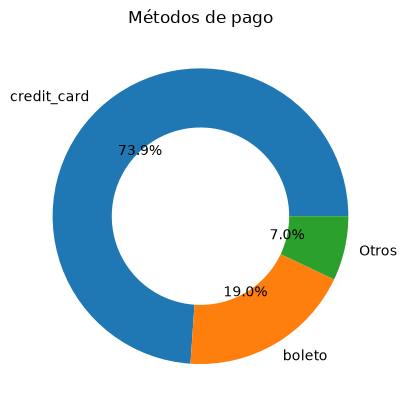

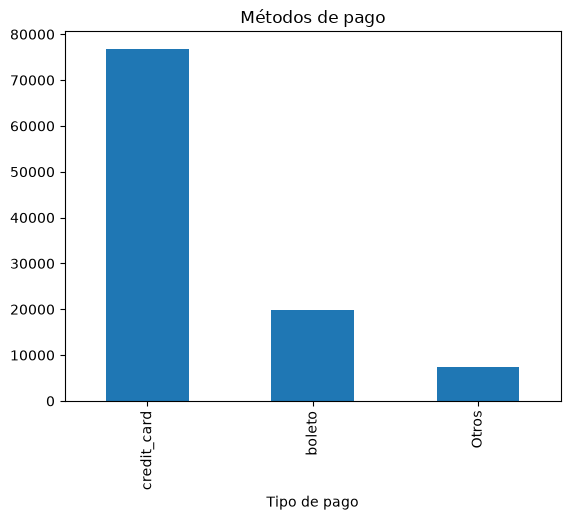

In [31]:
df7= payments
df7_top =  df7["payment_type"].value_counts().nlargest(2)
df7["otros"] = df7["payment_type"].apply(
    lambda x: x if x in df7_top else 'Otros'
)
otros = df7["otros"].value_counts()
fig,ax=plt.subplots()
otros.plot(
    kind="pie",
    wedgeprops={'width':0.4},
    autopct='%1.1f%%',
    title="Métodos de pago"
)
fig2,ax2=plt.subplots()
otros.plot(
    kind="bar",
    xlabel="Tipo de pago",
    title="Métodos de pago"
)

Con la gráfica de barras es más fácil denotar las magnitudes de cada uno de los métodos de pago

## 8 Barras agrupadas: monto promedio por mensualidades y método de pago
* Tomar order_payments.
* Crear rangos de payment_installments con pd.cut: 1, 2–3, 4–6, 7–10, más de 10.
* pivot_table: index = rango, columns = payment_type, values = payment_value, aggfunc = 'mean'.
* Barras agrupadas desplazando cada serie con x + i*ancho (o df.plot(kind='bar')).

<Axes: xlabel='Rango', ylabel='Pago promedio'>

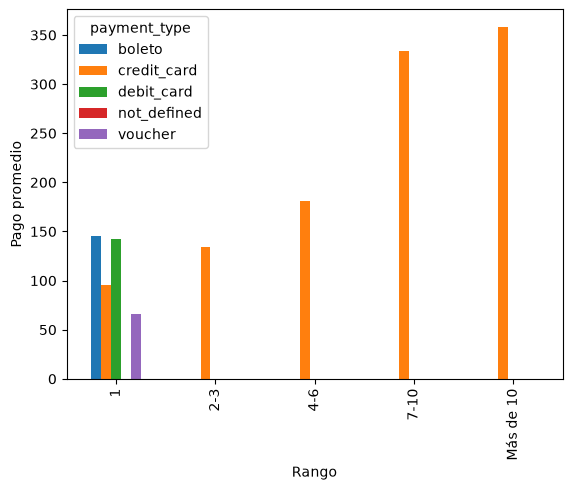

In [33]:
df8 = payments
df8["rango"]= pd.cut(df8["payment_installments"],
                     bins=[0,1,3,6,10,np.inf],
                     labels=["1","2-3","4-6","7-10","Más de 10"])
df8 = df8.pivot_table(index="rango",columns="payment_type",values="payment_value",aggfunc="mean")
df8.plot(kind="bar",
         ylabel="Pago promedio",
         xlabel="Rango"
)



## 9 Barras apiladas: estado del pedido por estado de la república
* Merge orders + customers por customer_id.
* pivot_table: index = customer_state, columns = order_status, values = order_id, aggfunc = 'count', fill_value=0.
* Normalizar por fila (dividir entre .sum(axis=1)) para tener porcentajes.
* Quedarse con los 10 estados con más pedidos.
* Apilar barras con un loop acumulando bottom.

<Axes: xlabel='Estado de orden', ylabel='Proporcion de pedidos'>

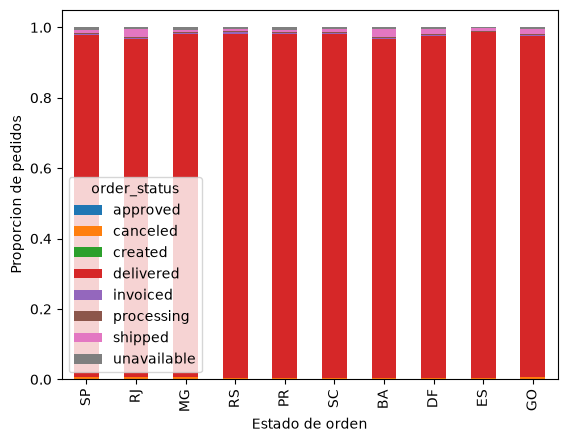

In [36]:
df9 = orders.merge(customers, on="customer_id", how="left")
df9 = df9.pivot_table(index = "customer_state",columns = "order_status",values= "order_id" ,aggfunc="count",fill_value=0)
df9_suma = df9.sum(axis=1)
df9_division = df9.div(df9_suma,axis=0)
df9_division_10 = df9_division.loc[df9_suma.nlargest(10).index]
df9_division_10.plot(kind="bar",
                         stacked="True",
                         xlabel="Estado de orden",
                         ylabel = "Proporcion de pedidos")

## 10.  Dispersión: peso del producto vs. costo de envío   *plt.scatter
* Merge order_items + products por product_id.
* Tomar product_weight_g y freight_value; quitar NaN.
* Muestrear con .sample(3000) (110k puntos saturan la gráfica).
* Graficar con alpha bajo; opcionalmente ejes en escala log.
* Extra: colorear por price con c= y agregar plt.colorbar().

<Axes: xlabel='freight_value', ylabel='price'>

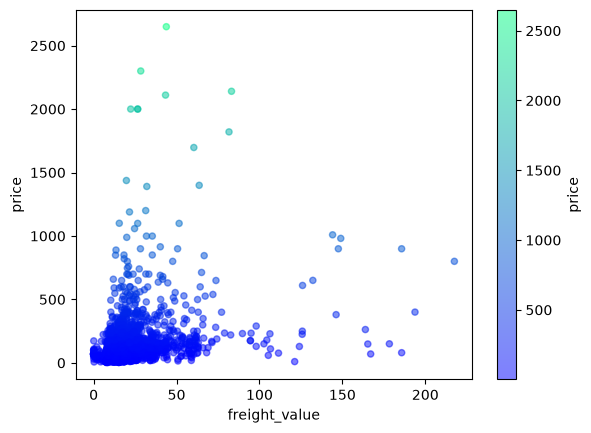

In [ ]:
df10 = order_items.merge(products, on="product_id", how="left")
df10 = df10[["product_weight_g", "freight_value","price"]]
df10.dropna(subset=["product_weight_g", "freight_value"])
df10 = df10.sample(3000)
df10.plot(
    kind="scatter",
    alpha = 0.5,
    x="freight_value",
    y="price",
    c="price",
    colormap = "winter"
    )

## 11 Mapa de calor: pedidos por día de la semana × hora
* De order_purchase_timestamp extraer .dt.dayofweek y .dt.hour.
* pivot_table: index = día, columns = hora, values = order_id, aggfunc = 'count'.
* plt.imshow(pivot, aspect='auto', cmap='YlOrRd').
* Etiquetas Lun–Dom en y, 0–23 en x; agregar colorbar.
* Extra: escribir valores en las celdas con doble loop de ax.text.

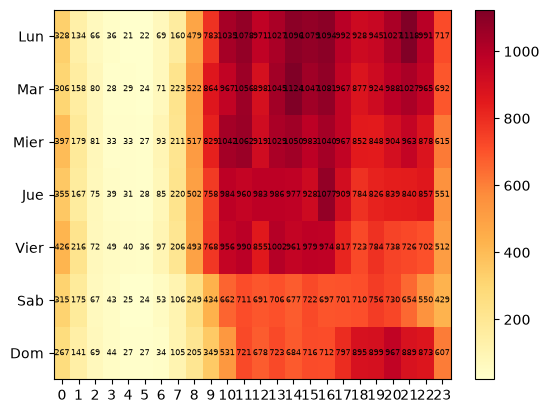

In [51]:
df11 = orders
df11["dias_semana"] = df11["order_purchase_timestamp"].dt.dayofweek
df11["horas"] = df11["order_purchase_timestamp"].dt.hour
df11 =  df11.pivot_table(index ="dias_semana", columns = "horas", values= "order_id",aggfunc="count")
mapa1 = plt.imshow(df11,aspect="auto",cmap ="YlOrRd" )
plt.yticks(range(7),["Lun","Mar","Mier","Jue","Vier","Sab","Dom"])
plt.xticks(range(24))
plt.colorbar(mapa1)
for i in range(7):
    for j in range(24):
        plt.text(j, i, df11.iloc[i, j],  ha="center", va="center",fontsize=6)

## 12 Dashboard final: subplots + doble eje
* Reutilizar los dataframes de las gráficas 1, 2, 5 y 11.
* fig, axes = plt.subplots(2, 2, figsize=(14,10)).
* Panel 1: pedidos por mes y, con twinx(), ingreso mensual en el segundo eje (merge orders + order_items, groupby mes, suma de price).
* Demás paneles: top categorías, boxplot de reseñas y heatmap.
* fig.suptitle, plt.tight_layout() y savefig('dashboard.png', dpi=150).

(Text(0.5, 0.98, 'Ejercicio 12'), None, None)

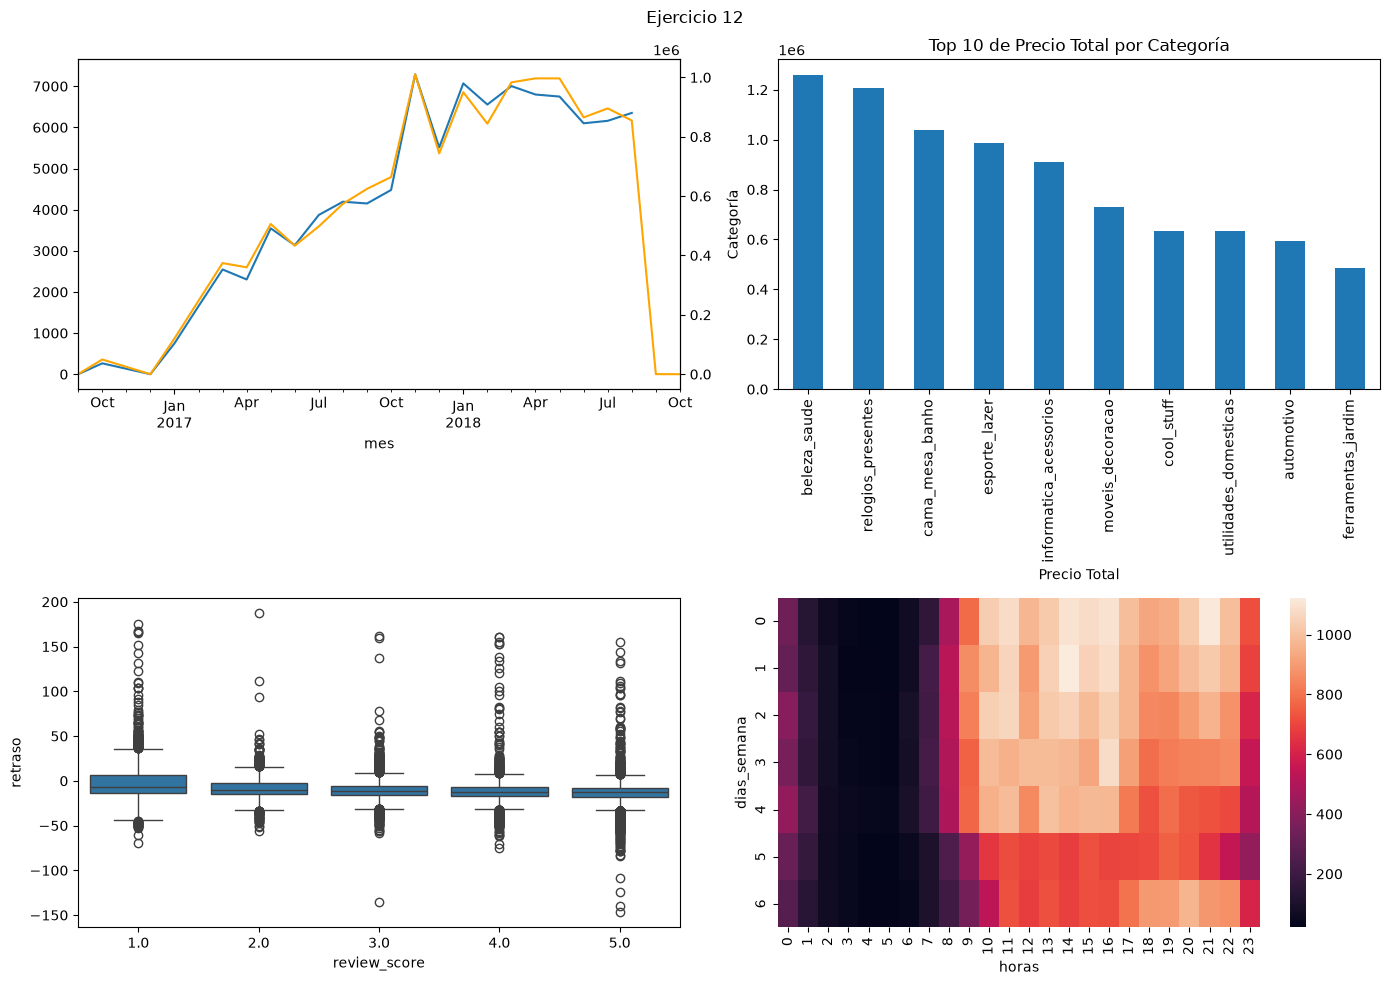

In [56]:
Uno = resultado1

fig, ax = plt.subplots(2,2,figsize=(14,10))
Uno.plot(ax= ax[0,0])
ingreso_mensual = orders.merge(order_items, on = "order_id", how = "left")
ingreso_mensual["month"] = ingreso_mensual["order_purchase_timestamp"].dt.to_period('M')
ingreso = ingreso_mensual.groupby("month")["price"].sum()
ax2 = ax [0,0].twinx()
ingreso.plot(ax=ax2, color="orange")

resultado2.plot(kind = "bar",
              title = "Top 10 de Precio Total por Categoría",
              xlabel = "Precio Total",
              ylabel = "Categoría",
              ax = ax[0,1])


sns.boxplot(data=df5, x="review_score", y="retraso", ax=ax[1,0])
sns.heatmap(df11, ax= ax[1,1])
plt.tight_layout()
fig.suptitle("Ejercicio 12"), plt.tight_layout(), plt.savefig('dashboard.png', dpi=600, bbox_inches="tight")